In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import requests
import pandas as pd

url = "https://api.worldbank.org/v2/country/all/indicator/NY.GDP.PCAP.CD"

params = {
    "format": "json",
    "date": "2023",
    "per_page": 500
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

data = response.json()

print("Total pages:", data[0]["pages"])
print("Total records:", data[0]["total"])
print("First record:", data[1][0])

Total pages: 1
Total records: 266
First record: {'indicator': {'id': 'NY.GDP.PCAP.CD', 'value': 'GDP per capita (current US$)'}, 'country': {'id': 'ZH', 'value': 'Africa Eastern and Southern'}, 'countryiso3code': 'AFE', 'date': '2023', 'value': 1571.13270407815, 'unit': '', 'obs_status': '', 'decimal': 1}


In [3]:
gdp_data = []

for record in data[1]:
    gdp_data.append({
        "Country": record["country"]["value"],
        "Country_Code": record["countryiso3code"],
        "Year": record["date"],
        "GDP_per_capita": record["value"]
    })

gdp_df = pd.DataFrame(gdp_data)

print("Dataset shape:", gdp_df.shape)
display(gdp_df.head(10))

print("\nMissing values:")
print(gdp_df.isnull().sum())

Dataset shape: (266, 4)


,Country,Country_Code,Year,GDP_per_capita
0,Africa Eastern and Southern,AFE,2023,1571.132704
1,Africa Western and Central,AFW,2023,1846.246811
2,Arab World,ARB,2023,7504.356377
3,Caribbean small states,CSS,2023,17609.682707
4,Central Europe and the Baltics,CEB,2023,22693.950447
5,Early-demographic dividend,EAR,2023,4212.169248
6,East Asia & Pacific,EAS,2023,13251.511980
7,East Asia & Pacific (excluding high income),EAP,2023,10126.430412
8,East Asia & Pacific (IDA & IBRD countries),TEA,2023,10240.347468
9,Euro area,EMU,2023,44797.644528



Missing values:
Country            0
Country_Code       0
Year               0
GDP_per_capita    14
dtype: int64


In [4]:
country_url = "https://api.worldbank.org/v2/country"

country_response = requests.get(
    country_url,
    params={"format": "json", "per_page": 500},
    timeout=30
)
country_response.raise_for_status()

countries = country_response.json()[1]

valid_codes = [
    country["id"]
    for country in countries
    if country["region"]["value"] != "Aggregates"
]

gdp_clean = gdp_df[
    gdp_df["Country_Code"].isin(valid_codes)
].copy()

gdp_clean = gdp_clean.dropna(subset=["GDP_per_capita"])

print("Original dataset:", gdp_df.shape)
print("Cleaned dataset:", gdp_clean.shape)

print("\nMissing values:")
print(gdp_clean.isnull().sum())

display(gdp_clean.head(10))

Original dataset: (266, 4)
Cleaned dataset: (204, 4)

Missing values:
Country           0
Country_Code      0
Year              0
GDP_per_capita    0
dtype: int64


,Country,Country_Code,Year,GDP_per_capita
49,Afghanistan,AFG,2023,413.757895
50,Albania,ALB,2023,9740.702341
51,Algeria,DZA,2023,5370.477235
53,Andorra,AND,2023,46812.448450
54,Angola,AGO,2023,2885.513491
55,Antigua and Barbuda,ATG,2023,22012.262595
56,Argentina,ARG,2023,14261.846567
57,Armenia,ARM,2023,8159.087210
58,Aruba,ABW,2023,34897.618393
59,Australia,AUS,2023,65058.377315


In [5]:
wiki_url = "https://en.wikipedia.org/wiki/List_of_countries_by_literacy_rate"

headers = {
    "User-Agent": "StudentDataCollectionProject/1.0 (educational research)"
}

response = requests.get(
    wiki_url,
    headers=headers,
    timeout=30
)

print("Status code:", response.status_code)

soup = BeautifulSoup(response.text, "html.parser")

tables = soup.find_all("table", class_="wikitable")

print("Number of tables found:", len(tables))

Status code: 200
Number of tables found: 3


In [6]:
for i, table in enumerate(tables):
    rows = table.find_all("tr")

    print(f"\nTable {i}")
    print("Number of rows:", len(rows))
    print("First row:", rows[0].get_text(" ", strip=True)[:250])


Table 0
Number of rows: 236
First row: Country Youth (15 to 24) Adult (25 to 64) Elderly (65+) Youth Gender Parity Index

Table 1
Number of rows: 198
First row: Country Literacy rate [ 13 ] [ 14 ] [ 1 ] [ text–source integrity? ]

Table 2
Number of rows: 11
First row: Territory Literacy rate (all) Male literacy Female literacy Gender difference [ a ] Year Note


In [7]:
literacy_table = pd.read_html(str(tables[0]))[0]

print("Table shape:", literacy_table.shape)
print("\nColumn names:")
print(literacy_table.columns.tolist())

display(literacy_table.head())

Table shape: (234, 9)

Column names:
[('Country', 'Country'), ('Youth (15 to 24)', 'Rate'), ('Youth (15 to 24)', 'Year'), ('Adult (25 to 64)', 'Rate'), ('Adult (25 to 64)', 'Year'), ('Elderly (65+)', 'Rate'), ('Elderly (65+)', 'Year'), ('Youth Gender Parity Index', 'Rate'), ('Youth Gender Parity Index', 'Year')]


/tmp/ipykernel_2888/2856934443.py:1: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  literacy_table = pd.read_html(str(tables[0]))[0]


Country Youth (15 to 24)          Adult (25 to 64)          \
            Country             Rate     Year             Rate    Year   
0     Afghanistan *             65.0  2020[5]             31.7  2011.0   
1         Albania *             99.2     2012             97.2  2012.0   
2         Algeria *             93.8     2008             75.1  2008.0   
3  American Samoa *             97.7     1980             97.3  1980.0   
4         Andorra *              NaN      NaN              NaN     NaN   

  Elderly (65+)         Youth Gender Parity Index          
           Rate    Year                      Rate    Year  
0          20.3  2011.0                       0.5  2011.0  
1          86.9  2012.0                       1.0  2012.0  
2          19.5  2008.0                       1.0  2008.0  
3          92.7  1980.0                       1.0  1980.0  
4           NaN     NaN                       NaN     NaN

In [8]:
literacy_df = literacy_table.iloc[:, [0, 3, 4]].copy()

literacy_df.columns = [
    "Country",
    "Literacy_Rate",
    "Literacy_Year"
]

print("Dataset shape:", literacy_df.shape)
display(literacy_df.head(10))

print("\nMissing values:")
print(literacy_df.isnull().sum())

Dataset shape: (234, 3)


,Country,Literacy_Rate,Literacy_Year
0,Afghanistan *,31.7,2011.0
1,Albania *,97.2,2012.0
2,Algeria *,75.1,2008.0
3,American Samoa *,97.3,1980.0
4,Andorra *,NaN,NaN
5,Angola *,66.0,2014.0
6,Anguilla *,95.4,1984.0
7,Antigua and Barbuda *,98.9,2015.0
8,Argentina *,99.1,2016.0
9,Armenia *,99.7,2011.0



Missing values:
Country           0
Literacy_Rate    63
Literacy_Year    63
dtype: int64


In [10]:
# Removing * from country names
literacy_df["Country"] = literacy_df["Country"].str.replace(
    "*", "", regex=False
).str.strip()

# Removing rows with missing literacy data
literacy_clean = literacy_df.dropna(
    subset=["Literacy_Rate", "Literacy_Year"]
).copy()

# Converting year to integer
literacy_clean["Literacy_Year"] = literacy_clean["Literacy_Year"].astype(int)

# Checking the cleaned dataset
print("Original dataset:", literacy_df.shape)
print("Cleaned dataset:", literacy_clean.shape)

print("\nMissing values:")
print(literacy_clean.isnull().sum())

display(literacy_clean.head(10))

Original dataset: (234, 3)
Cleaned dataset: (171, 3)

Missing values:
Country          0
Literacy_Rate    0
Literacy_Year    0
dtype: int64


,Country,Literacy_Rate,Literacy_Year
0,Afghanistan,31.7,2011
1,Albania,97.2,2012
2,Algeria,75.1,2008
3,American Samoa,97.3,1980
5,Angola,66.0,2014
6,Anguilla,95.4,1984
7,Antigua and Barbuda,98.9,2015
8,Argentina,99.1,2016
9,Armenia,99.7,2011
10,Aruba,96.8,2010


In [11]:
merged_df = pd.merge(
    gdp_clean,
    literacy_clean,
    on="Country",
    how="inner"
)

print("GDP dataset:", gdp_clean.shape)
print("Literacy dataset:", literacy_clean.shape)
print("Merged dataset:", merged_df.shape)

print("\nMissing values:")
print(merged_df.isnull().sum())

display(merged_df.head(10))

GDP dataset: (204, 4)
Literacy dataset: (171, 3)
Merged dataset: (137, 6)

Missing values:
Country           0
Country_Code      0
Year              0
GDP_per_capita    0
Literacy_Rate     0
Literacy_Year     0
dtype: int64


,Country,Country_Code,Year,GDP_per_capita,Literacy_Rate,Literacy_Year
0,Afghanistan,AFG,2023,413.757895,31.7,2011
1,Albania,ALB,2023,9740.702341,97.2,2012
2,Algeria,DZA,2023,5370.477235,75.1,2008
3,Angola,AGO,2023,2885.513491,66.0,2014
4,Antigua and Barbuda,ATG,2023,22012.262595,98.9,2015
5,Argentina,ARG,2023,14261.846567,99.1,2016
6,Armenia,ARM,2023,8159.087210,99.7,2011
7,Aruba,ABW,2023,34897.618393,96.8,2010
8,Azerbaijan,AZE,2023,7133.028380,99.8,2016
9,Bahrain,BHR,2023,29290.128422,86.5,2001


In [12]:
print("Duplicate countries:", merged_df["Country"].duplicated().sum())

print("\nLiteracy rate range:")
print(merged_df["Literacy_Rate"].agg(["min", "max"]))

print("\nLiteracy year range:")
print(merged_df["Literacy_Year"].agg(["min", "max"]))

unmatched = literacy_clean[
    ~literacy_clean["Country"].isin(gdp_clean["Country"])
]

print("\nUnmatched countries:", len(unmatched))
display(unmatched[["Country"]].head(20))

Duplicate countries: 0

Literacy rate range:
min    100.0
max     99.9
Name: Literacy_Rate, dtype: object

Literacy year range:
min    1983
max    2019
Name: Literacy_Year, dtype: int64

Unmatched countries: 34


,Country
3,American Samoa
6,Anguilla
30,Brunei
34,Cape Verde
44,Macau
47,Congo
48,DR Congo
51,Ivory Coast
53,Cuba
62,Egypt


In [16]:
for country in unmatched["Country"]:
    matches = gdp_clean[
        gdp_clean["Country"].str.contains(
            country.split()[0],
            case=False,
            regex=False
        )
    ]["Country"].tolist()

    if matches:
        print(country, "→", matches)

Brunei → ['Brunei Darussalam']
Congo → ['Congo, Dem. Rep.', 'Congo, Rep.']
DR Congo → ['Lao PDR']
Egypt → ['Egypt, Arab Rep.']
French Guiana → ['French Polynesia']
Gambia → ['Gambia, The']
Iran → ['Iran, Islamic Rep.']
North Korea → ['North Macedonia']
Puerto Rico → ['Puerto Rico (US)']
Russia → ['Russian Federation']
South Sudan → ['South Africa']
Venezuela → ['Venezuela, RB']


In [17]:
country_mapping = {
    "Brunei": "Brunei Darussalam",
    "Congo": "Congo, Rep.",
    "DR Congo": "Congo, Dem. Rep.",
    "Egypt": "Egypt, Arab Rep.",
    "Gambia": "Gambia, The",
    "Iran": "Iran, Islamic Rep.",
    "Russia": "Russian Federation",
    "South Sudan": "South Sudan",
    "Venezuela": "Venezuela, RB",
    "Kyrgyzstan": "Kyrgyz Republic",
    "Laos": "Lao PDR"
}

literacy_clean["Country"] = literacy_clean["Country"].replace(country_mapping)

merged_df = pd.merge(
    gdp_clean,
    literacy_clean,
    on="Country",
    how="inner"
)

print("Merged dataset shape:", merged_df.shape)
print("Missing values:")
print(merged_df.isnull().sum())

Merged dataset shape: (147, 6)
Missing values:
Country           0
Country_Code      0
Year              0
GDP_per_capita    0
Literacy_Rate     0
Literacy_Year     0
dtype: int64


In [18]:
print("Dataset shape:", merged_df.shape)

print("\nDuplicate countries:")
print(merged_df["Country"].duplicated().sum())

print("\nGDP year:")
print(merged_df["Year"].unique())

print("\nLiteracy year range:")
print(merged_df["Literacy_Year"].min(),
      merged_df["Literacy_Year"].max())

print("\nLiteracy rate range:")
print(merged_df["Literacy_Rate"].min(),
      merged_df["Literacy_Rate"].max())

print("\nFinal dataset:")
display(merged_df.head(10))

Dataset shape: (147, 6)

Duplicate countries:
0

GDP year:
['2023']

Literacy year range:
1983 2019

Literacy rate range:
100.0 99.9

Final dataset:


,Country,Country_Code,Year,GDP_per_capita,Literacy_Rate,Literacy_Year
0,Afghanistan,AFG,2023,413.757895,31.7,2011
1,Albania,ALB,2023,9740.702341,97.2,2012
2,Algeria,DZA,2023,5370.477235,75.1,2008
3,Angola,AGO,2023,2885.513491,66.0,2014
4,Antigua and Barbuda,ATG,2023,22012.262595,98.9,2015
5,Argentina,ARG,2023,14261.846567,99.1,2016
6,Armenia,ARM,2023,8159.087210,99.7,2011
7,Aruba,ABW,2023,34897.618393,96.8,2010
8,Azerbaijan,AZE,2023,7133.028380,99.8,2016
9,Bahrain,BHR,2023,29290.128422,86.5,2001


In [21]:
merged_df["Literacy_Rate"] = pd.to_numeric(
    merged_df["Literacy_Rate"].astype(str).str.replace(
        r"\[\d+\]", "", regex=True
    ),
    errors="coerce"
)

print("Missing values:", merged_df["Literacy_Rate"].isnull().sum())
print("Data type:", merged_df["Literacy_Rate"].dtype)

Missing values: 0
Data type: float64


In [22]:
# Remove Wikipedia reference numbers
merged_df["Literacy_Rate"] = (
    merged_df["Literacy_Rate"]
    .astype(str)
    .str.replace(r"\[\d+\]", "", regex=True)
)

# Convert literacy rates to numbers
merged_df["Literacy_Rate"] = pd.to_numeric(
    merged_df["Literacy_Rate"],
    errors="coerce"
)

# Check results
print("Missing values:", merged_df["Literacy_Rate"].isnull().sum())
print("Data type:", merged_df["Literacy_Rate"].dtype)

display(merged_df.head())

Missing values: 0
Data type: float64


,Country,Country_Code,Year,GDP_per_capita,Literacy_Rate,Literacy_Year
0,Afghanistan,AFG,2023,413.757895,31.7,2011
1,Albania,ALB,2023,9740.702341,97.2,2012
2,Algeria,DZA,2023,5370.477235,75.1,2008
3,Angola,AGO,2023,2885.513491,66.0,2014
4,Antigua and Barbuda,ATG,2023,22012.262595,98.9,2015


In [23]:
correlation = merged_df["Literacy_Rate"].corr(
    merged_df["GDP_per_capita"]
)

print("Correlation between literacy rate and GDP per capita:")
print(round(correlation, 3))

print("\nSummary statistics:")
display(
    merged_df[["Literacy_Rate", "GDP_per_capita"]].describe()
)

Correlation between literacy rate and GDP per capita:
0.419

Summary statistics:


,Literacy_Rate,GDP_per_capita
count,147.000000,147.000000
mean,82.617007,11645.131280
std,20.154385,15818.846236
min,22.300000,249.795164
25%,74.250000,2097.453713
50%,92.000000,5754.428339
75%,98.100000,14920.098165
max,100.000000,100065.233841


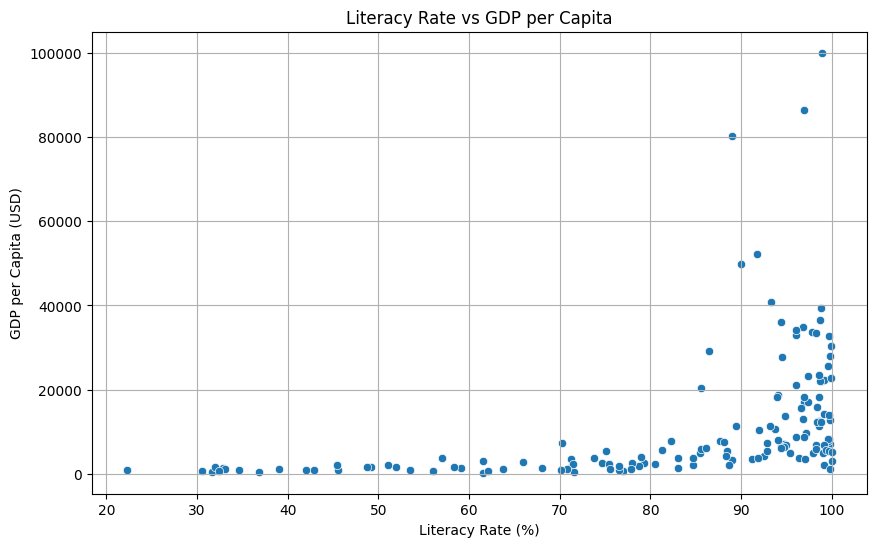

In [24]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=merged_df,
    x="Literacy_Rate",
    y="GDP_per_capita"
)

plt.title("Literacy Rate vs GDP per Capita")
plt.xlabel("Literacy Rate (%)")
plt.ylabel("GDP per Capita (USD)")
plt.grid(True)
plt.show()

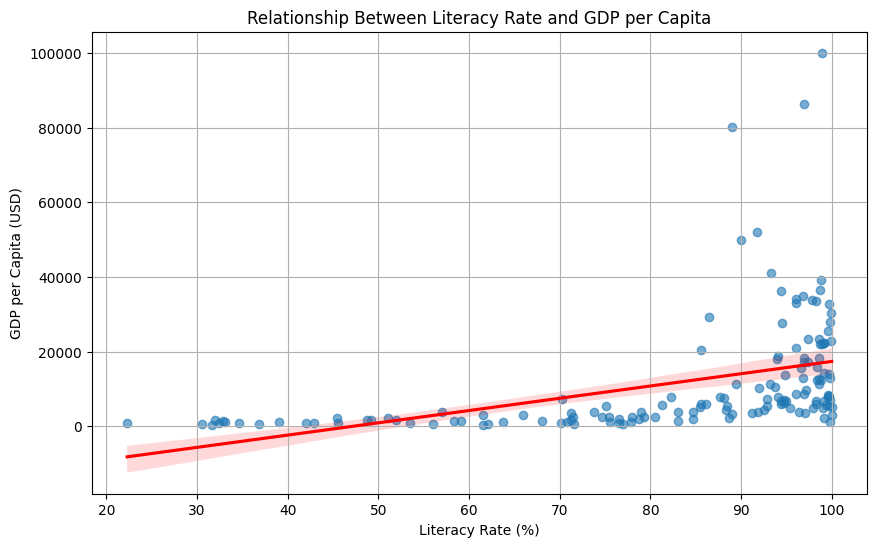

In [25]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=merged_df,
    x="Literacy_Rate",
    y="GDP_per_capita",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Relationship Between Literacy Rate and GDP per Capita")
plt.xlabel("Literacy Rate (%)")
plt.ylabel("GDP per Capita (USD)")
plt.grid(True)
plt.show()

In [26]:
merged_df.to_csv("SIS1_Education_Economic_Development.csv", index=False)

print("Dataset saved successfully!")
print("Rows and columns:", merged_df.shape)

Dataset saved successfully!
Rows and columns: (147, 6)


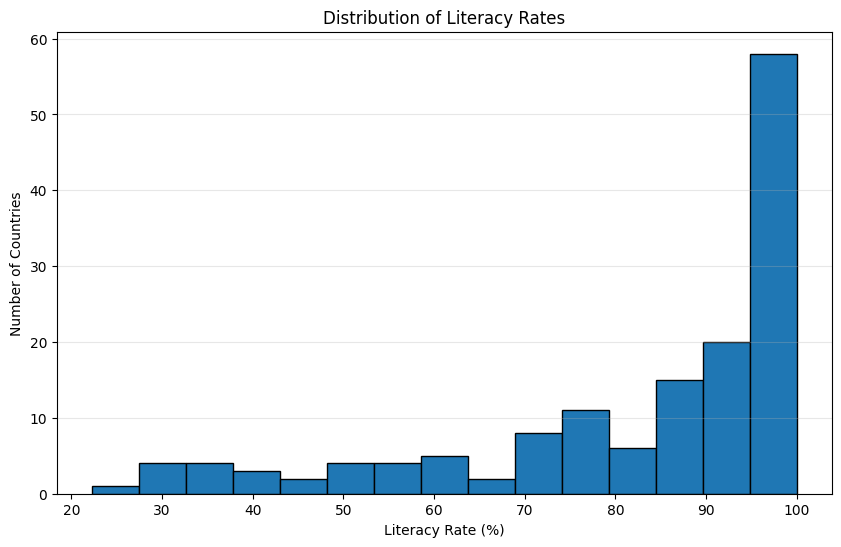

In [27]:
plt.figure(figsize=(10, 6))

plt.hist(merged_df["Literacy_Rate"], bins=15, edgecolor="black")

plt.title("Distribution of Literacy Rates")
plt.xlabel("Literacy Rate (%)")
plt.ylabel("Number of Countries")
plt.grid(axis="y", alpha=0.3)

plt.show()